# Amazon Review Intelligence System

**Dataset:** Amazon *All Beauty* reviews, 20,000-review sample (`all_beauty_reviews_sample_20000.jsonl`)

**Goal:** Use PySpark to clean the reviews, label their sentiment, and build simple models.

**Models used (kept simple on purpose)**
- Logistic Regression and Naive Bayes for sentiment classification
- K-Means for grouping similar reviews

**Contents**
1. Setup
2. Load & Inspect Data
3. Clean Data & Create Sentiment Labels
4. Sentiment Exploration
5. Text Features (TF-IDF)
6. Sentiment Classification
7. K-Means Clustering
8. Summary

## 1. Setup

In [1]:
import os
import sys

# Make Spark use the same Python as this notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, concat_ws, length, lower, regexp_replace, trim, when
from pyspark.sql.functions import sum as spark_sum
from pyspark.ml import Pipeline
from pyspark.ml.feature import Tokenizer, StopWordsRemover, CountVectorizer, IDF, StringIndexer
from pyspark.ml.classification import LogisticRegression, NaiveBayes
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, ClusteringEvaluator

spark = (
    SparkSession.builder
    .appName("AmazonReviewIntelligence")
    .master("local[*]")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)

Spark version: 3.5.9


## 2. Load & Inspect Data

In [2]:
df = spark.read.json("all_beauty_reviews_sample_20000.jsonl")

print("Total reviews:", df.count())
df.printSchema()
df.show(5, truncate=50)

Total reviews: 20000
root
 |-- asin: string (nullable = true)
 |-- helpful_vote: long (nullable = true)
 |-- images: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- attachment_type: string (nullable = true)
 |    |    |-- large_image_url: string (nullable = true)
 |    |    |-- medium_image_url: string (nullable = true)
 |    |    |-- small_image_url: string (nullable = true)
 |-- parent_asin: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- text: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- title: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- verified_purchase: boolean (nullable = true)

+----------+------------+------+-----------+------+--------------------------------------------------+-------------+-----------------------------------------+----------------------------+-----------------+
|      asin|helpful_vote|images|parent_asin|rating|                                          

In [3]:
# Missing values per column
missing = df.select([
    spark_sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in df.columns
])
missing.show()

# Rating distribution
df.groupBy("rating").count().orderBy("rating").show()

+----+------------+------+-----------+------+----+---------+-----+-------+-----------------+
|asin|helpful_vote|images|parent_asin|rating|text|timestamp|title|user_id|verified_purchase|
+----+------------+------+-----------+------+----+---------+-----+-------+-----------------+
|   0|           0|     0|          0|     0|   0|        0|    0|      0|                0|
+----+------------+------+-----------+------+----+---------+-----+-------+-----------------+

+------+-----+
|rating|count|
+------+-----+
|   1.0| 1901|
|   2.0| 1206|
|   3.0| 1924|
|   4.0| 3034|
|   5.0|11935|
+------+-----+



## 3. Clean Data & Create Sentiment Labels

Steps: remove duplicates → keep useful columns → merge title and text → drop empty reviews → label sentiment → clean the text.

Sentiment rule: rating 1-2 → **Negative**, 3 → **Neutral**, 4-5 → **Positive**.

In [4]:
rows_before = df.count()

df_clean = (
    df.dropDuplicates()
    .select("asin", "user_id", "rating", "title", "text")
    .withColumn("review_text", trim(concat_ws(" ", col("title"), col("text"))))
    .filter(length(col("review_text")) > 0)
)

# Sentiment label from rating
df_clean = df_clean.withColumn(
    "sentiment",
    when(col("rating") <= 2, "Negative")
    .when(col("rating") == 3, "Neutral")
    .otherwise("Positive")
)

# Text cleaning: lowercase, keep only letters/numbers/spaces, collapse spaces
df_clean = df_clean.withColumn(
    "clean_text",
    trim(regexp_replace(
        regexp_replace(lower(col("review_text")), "[^a-zA-Z0-9\\s]", ""),
        "\\s+", " "
    ))
)

print("Reviews before cleaning:", rows_before)
print("Reviews after cleaning: ", df_clean.count())
df_clean.select("rating", "sentiment", "clean_text").show(5, truncate=80)

Reviews before cleaning: 20000
Reviews after cleaning:  19964
+------+---------+--------------------------------------------------------------------------------+
|rating|sentiment|                                                                      clean_text|
+------+---------+--------------------------------------------------------------------------------+
|   2.0| Negative|vegetal messy flower balls not sure why anyone would use this for anything bu...|
|   3.0|  Neutral|kidsized shower caps best used to cover small serving bowls this single layer...|
|   5.0| Positive|awesome product use this stuff a lot always ordering more as i use it frequently|
|   5.0| Positive|great quality i bought these for my 3 year old daughter who is moon obsessed ...|
|   1.0| Negative|                           dont waste money does not work comes right off finger|
+------+---------+--------------------------------------------------------------------------------+
only showing top 5 rows



## 4. Sentiment Exploration

  sentiment  count  percentage
0  Positive  14939       74.83
1  Negative   3103       15.54
2   Neutral   1922        9.63


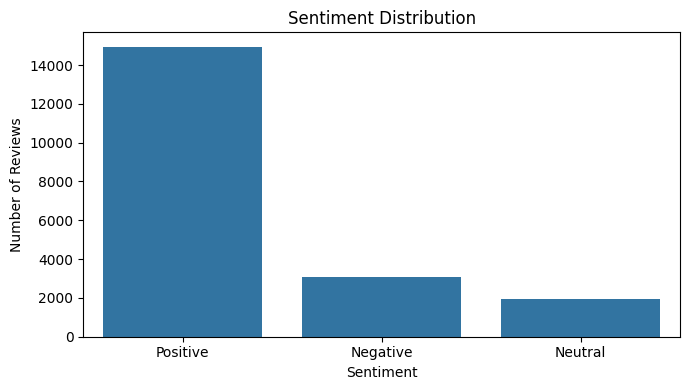

In [5]:
total = df_clean.count()

sentiment_counts = (
    df_clean.groupBy("sentiment").count().toPandas()
    .sort_values("count", ascending=False)
    .reset_index(drop=True)
)
sentiment_counts["percentage"] = (sentiment_counts["count"] / total * 100).round(2)
print(sentiment_counts)

plt.figure(figsize=(7, 4))
sns.barplot(data=sentiment_counts, x="sentiment", y="count")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

## 5. Text Features (TF-IDF)

One preprocessing pipeline is fitted once and shared by every model below:
tokenize → remove stop words → count words → TF-IDF → turn sentiment into a numeric label.

Negation words (`not`, `no`, `nor`) are kept because they carry sentiment.

In [6]:
# 80/20 train/test split
train_df, test_df = df_clean.randomSplit([0.8, 0.2], seed=42)
print("Training reviews:", train_df.count())
print("Testing reviews: ", test_df.count())

tokenizer = Tokenizer(inputCol="clean_text", outputCol="words")

remover = StopWordsRemover(inputCol="words", outputCol="filtered_words")
remover.setStopWords([w for w in remover.getStopWords() if w not in ["not", "no", "nor"]])

cv = CountVectorizer(inputCol="filtered_words", outputCol="raw_features", vocabSize=10000, minDF=2)
idf = IDF(inputCol="raw_features", outputCol="features")
indexer = StringIndexer(inputCol="sentiment", outputCol="label")

prep_pipeline = Pipeline(stages=[tokenizer, remover, cv, idf, indexer])
prep_model = prep_pipeline.fit(train_df)

train_features = prep_model.transform(train_df).cache()
test_features = prep_model.transform(test_df).cache()

vocabulary = prep_model.stages[2].vocabulary
label_names = prep_model.stages[4].labelsArray[0]   # index -> sentiment name

print("Vocabulary size:", len(vocabulary))
print("Labels:", {i: name for i, name in enumerate(label_names)})

Training reviews: 16093
Testing reviews:  3871
Vocabulary size: 10000
Labels: {0: 'Positive', 1: 'Negative', 2: 'Neutral'}


## 6. Sentiment Classification

Two simple models: **Logistic Regression** and **Naive Bayes**.

In [7]:
accuracy_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")


def evaluate(name, predictions):
    """Print accuracy, weighted F1 and per-class precision/recall. Returns (accuracy %, F1)."""
    acc = accuracy_eval.evaluate(predictions)
    f1 = f1_eval.evaluate(predictions)
    print(f"{name}: Accuracy = {acc * 100:.2f}%, Weighted F1 = {f1:.4f}")

    for i, sentiment in enumerate(label_names):
        precision = MulticlassClassificationEvaluator(
            labelCol="label", predictionCol="prediction",
            metricName="precisionByLabel", metricLabel=float(i)
        ).evaluate(predictions)
        recall = MulticlassClassificationEvaluator(
            labelCol="label", predictionCol="prediction",
            metricName="recallByLabel", metricLabel=float(i)
        ).evaluate(predictions)
        print(f"   {sentiment:<9} precision = {precision:.4f}, recall = {recall:.4f}")

    return round(acc * 100, 2), round(f1, 4)

### 6.1 Logistic Regression

In [8]:
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=50, regParam=0.01)
lr_model = lr.fit(train_features)
lr_predictions = lr_model.transform(test_features)

lr_acc, lr_f1 = evaluate("Logistic Regression", lr_predictions)

Logistic Regression: Accuracy = 82.08%, Weighted F1 = 0.8113
   Positive  precision = 0.8899, recall = 0.9360
   Negative  precision = 0.6809, recall = 0.6096
   Neutral   precision = 0.3277, recall = 0.2481


### 6.2 Naive Bayes

In [9]:
nb = NaiveBayes(featuresCol="features", labelCol="label", modelType="multinomial", smoothing=1.0)
nb_model = nb.fit(train_features)
nb_predictions = nb_model.transform(test_features)

nb_acc, nb_f1 = evaluate("Naive Bayes", nb_predictions)

Naive Bayes: Accuracy = 77.08%, Weighted F1 = 0.7855
   Positive  precision = 0.9196, recall = 0.8441
   Negative  precision = 0.5742, recall = 0.6429
   Neutral   precision = 0.2724, recall = 0.3964


### 6.3 Model comparison

In [10]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    "Accuracy (%)": [lr_acc, nb_acc],
    "Weighted F1": [lr_f1, nb_f1],
}).sort_values("Weighted F1", ascending=False).reset_index(drop=True)

display(model_comparison)

best = model_comparison.iloc[0]
best_name = best["Model"]
best_predictions = lr_predictions if best_name == "Logistic Regression" else nb_predictions
print("Best model:", best_name)

,Model,Accuracy (%),Weighted F1
0,Logistic Regression,82.08,0.8113
1,Naive Bayes,77.08,0.7855


Best model: Logistic Regression


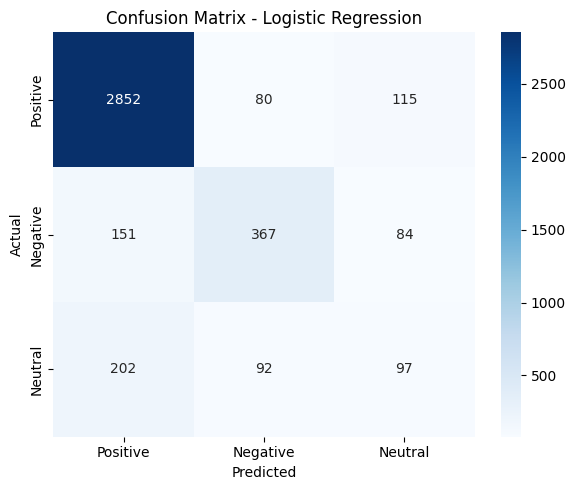

In [11]:
# Confusion matrix for the best model
cm = (
    best_predictions.groupBy("label", "prediction").count().toPandas()
    .pivot(index="label", columns="prediction", values="count").fillna(0)
)
cm.index = [label_names[int(i)] for i in cm.index]
cm.columns = [label_names[int(i)] for i in cm.columns]

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 7. K-Means Clustering

Group similar reviews using the same TF-IDF features. Set `K` below to change the number of clusters.

K = 2, silhouette = 0.8644
K = 3, silhouette = 0.5869
K = 4, silhouette = 0.1994
K = 5, silhouette = -0.1216
K = 6, silhouette = -0.1196


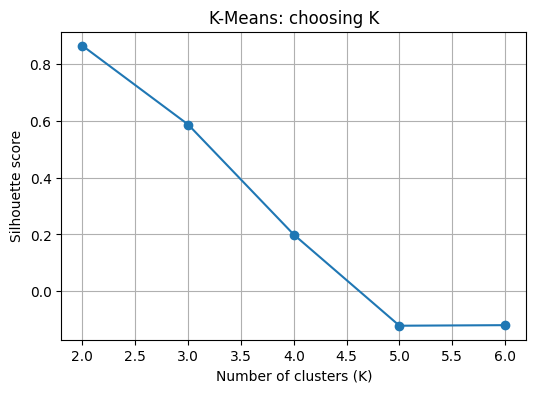

In [12]:
K = 5

all_features = prep_model.transform(df_clean).select("features", "sentiment").cache()

# Compare a few K values on a small sample (silhouette is slow on large data)
sample = all_features.sample(False, 0.1, seed=42).limit(2000).cache()
silhouette_eval = ClusteringEvaluator(featuresCol="features", predictionCol="cluster",
                                      metricName="silhouette", distanceMeasure="squaredEuclidean")

scores = []
for k in [2, 3, 4, 5, 6]:
    km_model = KMeans(k=k, featuresCol="features", predictionCol="cluster", seed=42, maxIter=20).fit(sample)
    score = silhouette_eval.evaluate(km_model.transform(sample))
    scores.append((k, score))
    print(f"K = {k}, silhouette = {score:.4f}")

plt.figure(figsize=(6, 4))
plt.plot([s[0] for s in scores], [s[1] for s in scores], marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("K-Means: choosing K")
plt.grid(True)
plt.show()

In [13]:
# Final K-Means model
kmeans_model = KMeans(k=K, featuresCol="features", predictionCol="cluster", seed=42, maxIter=20).fit(all_features)
clustered = kmeans_model.transform(all_features)

# Cluster sizes
clustered.groupBy("cluster").count().orderBy("cluster").show()

# Sentiment mix inside each cluster (%)
cluster_sentiment = clustered.groupBy("cluster", "sentiment").count().toPandas()
display(
    cluster_sentiment.pivot(index="cluster", columns="sentiment", values="count")
    .fillna(0)
    .pipe(lambda t: t.div(t.sum(axis=1), axis=0) * 100)
    .round(2)
)

# Top words in each cluster
for i, center in enumerate(kmeans_model.clusterCenters()):
    top_words = [vocabulary[j] for j in np.argsort(center)[-10:][::-1]]
    print(f"Cluster {i}: {top_words}")

+-------+-----+
|cluster|count|
+-------+-----+
|      0|18650|
|      1|    1|
|      2|    1|
|      3| 1304|
|      4|    8|
+-------+-----+



sentiment,Negative,Neutral,Positive
cluster,,,
0,16.06,9.49,74.46
1,0.00,0.00,100.00
2,0.00,0.00,100.00
3,8.28,11.66,80.06
4,0.00,12.50,87.50


Cluster 0: ['hair', 'not', 'great', 'love', 'good', 'product', 'like', 'use', 'nice', 'well']
Cluster 1: ['agent', '1', 'br', 'emollient', 'ingredient', 'skin', 'humectant', 'acid', 'emulsifying', 'alcohol']
Cluster 2: ['replenish', 'nourish', 'conditioner', 'tresemme', 'coconut', 'milk', 'vera', 'silicones', 'shampoo', 'aloe']
Cluster 3: ['br', 'skin', 'hair', 'not', 'one', 'use', 'like', 'product', 'face', 'oil']
Cluster 4: ['skin', 'oil', 'br', 'la', 'leaf', 'n', 'seed', 'organic', 'extract', 'lotion']


## 8. Summary

In [14]:
print("=" * 50)
print("AMAZON REVIEW INTELLIGENCE SYSTEM")
print("=" * 50)
display(model_comparison)
print(f"\nBest classifier: {best_name} "
      f"(accuracy {best['Accuracy (%)']}%, weighted F1 {best['Weighted F1']})")
print(f"K-Means grouped the reviews into {K} clusters (see section 7).")

AMAZON REVIEW INTELLIGENCE SYSTEM


,Model,Accuracy (%),Weighted F1
0,Logistic Regression,82.08,0.8113
1,Naive Bayes,77.08,0.7855



Best classifier: Logistic Regression (accuracy 82.08%, weighted F1 0.8113)
K-Means grouped the reviews into 5 clusters (see section 7).
